# Solutions to notebook 4: Polynomial interpolation and Chebyshev points

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/04_polynomial_interpolation.ipynb)

Worked solutions to the exercises at the end of [notebook 4](../notebooks/04_polynomial_interpolation.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 4
def barycentric_weights(nodes):
    """Barycentric weights λ_j = 1 / prod_{k≠j} (x_j - x_k) for any set of distinct points."""
    nodes = np.asarray(nodes, dtype=float)
    dx = nodes[:, None] - nodes[None, :]
    np.fill_diagonal(dx, 1.0)
    return 1 / dx.prod(axis=1)

def lagrange_interpolate(nodes, values, x_eval):
    """Evaluate the polynomial interpolant through (nodes, values) at x_eval, by the barycentric formula."""
    nodes, values = np.asarray(nodes, dtype=float), np.asarray(values, dtype=float)
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - nodes[None, :]
    exact = diff == 0                                           # evaluation points that hit a node
    diff[exact] = 1.0
    ratio = barycentric_weights(nodes) / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points x_j = cos(jπ/N).

    Uses the barycentric formula, which is numerically stable for any N.
    """
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

def equispaced_points(N):
    return np.linspace(-1, 1, N + 1)

def chebyshev_points(N):
    return np.cos(np.pi * np.arange(N + 1) / N)                # x_0 = 1 down to x_N = -1

def potential(z, nodes):
    """φ_N(z) = (1/N) Σ log|z - x_j| for the N + 1 points in nodes; z may be complex."""
    return np.log(np.abs(np.asarray(z)[..., None] - nodes)).sum(axis=-1) / (len(nodes) - 1)

def equispaced_limit_potential(z):
    z = np.asarray(z, dtype=complex)
    return -1 + np.real((z + 1) * np.log(z + 1) - (z - 1) * np.log(z - 1)) / 2

def lebesgue_constant(nodes, n_eval=20001):
    """Largest value of Σ|ℓ_j(x)| on [-1, 1], sampled at n_eval points."""
    x_eval = np.linspace(-1, 1, n_eval)
    diff = x_eval[:, None] - nodes[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    node_polynomial = np.abs(diff).prod(axis=1)                # |p(x)|
    lebesgue_function = node_polynomial * (np.abs(barycentric_weights(nodes)) / np.abs(diff)).sum(axis=1)
    lebesgue_function[exact.any(axis=1)] = 1.0                 # at a node the sum is exactly 1
    return lebesgue_function.max()

x_fine = np.linspace(-1, 1, 2001)                              # where the interpolation errors are measured

## Exercise 1

Compute the barycentric weights $\lambda_0, \dots, \lambda_3$ of the four Chebyshev points
with $N = 3$ by hand from the definition in 4.1, and check them with `barycentric_weights`.
Confirm that they are $2^{N-1}/N$ times the pattern $\tfrac12, -1, 1, -\tfrac12$. Then
interpolate $f(x) = x^3 - x$ through those four points and verify that
`barycentric_interpolate` returns $f(0.3)$ exactly.

The four points are $x = 1, \tfrac12, -\tfrac12, -1$. Each weight is one over a product of
three differences, for example
$\lambda_0 = 1/\big[(1 - \tfrac12)(1 + \tfrac12)(1 + 1)\big] = 1/\tfrac32 = \tfrac23$ and
$\lambda_1 = 1/\big[(\tfrac12 - 1)(\tfrac12 + \tfrac12)(\tfrac12 + 1)\big] = 1/(-\tfrac34) = -\tfrac43$.
By the symmetry of the points $\lambda_2 = -\lambda_1$ and $\lambda_3 = -\lambda_0$. The common
factor is $2^{N-1}/N = \tfrac43$, and $\tfrac43 \times (\tfrac12, -1, 1, -\tfrac12)$ is the same list.
A cubic through four points is reproduced exactly, so the interpolant must return
$f(0.3) = 0.027 - 0.3 = -0.273$.

In [3]:
N = 3
x = chebyshev_points(N)
weights = barycentric_weights(x)
by_hand = np.array([2 / 3, -4 / 3, 4 / 3, -2 / 3])
pattern = np.array([1 / 2, -1, 1, -1 / 2])

f = lambda x: x**3 - x
value = barycentric_interpolate(f(x), 0.3)[0]
print("points: ", x)
print("weights:", weights)
print("weights divided by 2^(N-1)/N:", weights / (2 ** (N - 1) / N))
print(f"interpolant at 0.3: {value:.15f}")

points:  [ 1.   0.5 -0.5 -1. ]
weights: [ 0.66666667 -1.33333333  1.33333333 -0.66666667]
weights divided by 2^(N-1)/N: [ 0.5 -1.   1.  -0.5]
interpolant at 0.3: -0.273000000000000


In [4]:
# verify: the weights against the values worked out by hand, the interpolant against the cubic itself
assert np.allclose(weights, by_hand, rtol=1e-13)
assert np.allclose(weights, 2 ** (N - 1) / N * pattern, rtol=1e-13)
assert abs(value - (-0.273)) < 1e-13

**Answer.** $\lambda = \big(\tfrac23, -\tfrac43, \tfrac43, -\tfrac23\big)$, which is
$\tfrac43$ times the pattern $\tfrac12, -1, 1, -\tfrac12$, and the interpolant returns
$f(0.3) = -0.273$ to rounding. `barycentric_interpolate` uses only the pattern: the
factor $\tfrac43$ appears in the numerator and the denominator of the barycentric formula and
cancels.

## Exercise 2

The family $f(x) = \dfrac{1}{1 + (x/c)^2}$ has poles at $\pm ic$. According to 4.4,
interpolation in equally spaced points converges on the whole interval only if the poles lie
outside the lens that crosses the imaginary axis at $\pm0.5255i$. Test this for $c = 0.4$ and
$c = 0.7$: tabulate the largest error on $[-1, 1]$ for $N = 10, 20, 30, 40$ with
`lagrange_interpolate`. Which case converges? Then confirm the number 0.5255 by solving
$\phi(iy) = -1 + \log 2$ with `scipy.optimize.brentq` and `equispaced_limit_potential`.

The pole at $0.4i$ is inside the lens and the pole at $0.7i$ is outside it, so the first case
should diverge near the ends and the second should converge. The estimate of 4.4 also gives the
rates: the largest error should behave like $e^{N[\phi(1) - \phi(ic)]}$, with
$\phi(1) = -1 + \log 2$ and $\phi(ic)$ from `equispaced_limit_potential`.

In [5]:
N_table = np.array([10, 20, 30, 40])
errors, predicted_rate, measured_rate = {}, {}, {}
for c in (0.4, 0.7):
    f = lambda x: 1 / (1 + (x / c) ** 2)
    errors[c] = np.array([np.abs(lagrange_interpolate(equispaced_points(N), f(equispaced_points(N)), x_fine) - f(x_fine)).max()
                          for N in N_table])
    predicted_rate[c] = (-1 + np.log(2)) - equispaced_limit_potential(1j * c)
    measured_rate[c] = np.polyfit(N_table, np.log(errors[c]), 1)[0]

print("  N     c = 0.4     c = 0.7")
for N, e_inside, e_outside in zip(N_table, errors[0.4], errors[0.7]):
    print(f"{N:3d} {e_inside:11.1e} {e_outside:11.1e}")
for c in (0.4, 0.7):
    print(f"c = {c}: error ∝ exp({measured_rate[c]:+.3f} N) measured, exp({predicted_rate[c]:+.3f} N) predicted")

  N     c = 0.4     c = 0.7
 10     2.5e-01     1.2e-02
 20     6.0e-01     1.2e-03
 30     1.9e+00     1.5e-04
 40     6.3e+00     2.0e-05
c = 0.4: error ∝ exp(+0.108 N) measured, exp(+0.143 N) predicted
c = 0.7: error ∝ exp(-0.213 N) measured, exp(-0.178 N) predicted


For the edge of the lens, set $z = iy$ in the limit potential and look for the height $y$ at
which it equals the potential of the end points, $-1 + \log 2$. The potential rises with $y$,
it is $-1$ at $y = 0$, and it is positive at $y = 1$, so the root is bracketed by 0.1 and 1.

In [6]:
y_lens = brentq(lambda y: equispaced_limit_potential(1j * y) - (-1 + np.log(2)), 0.1, 1.0, xtol=1e-14)
print(f"the lens crosses the imaginary axis at y = {y_lens:.6f}")

the lens crosses the imaginary axis at y = 0.525525


In [7]:
# verify: divergence and convergence as the lens predicts, the measured rates against the potential
# estimate (a check of sign and size only, to 30 %, because the estimate leaves out a slowly varying factor), and the crossing point against the potential of 4000 actual equally spaced points
assert np.all(np.diff(errors[0.4]) > 0) and np.all(np.diff(errors[0.7]) < 0)
assert all(abs(measured_rate[c] / predicted_rate[c] - 1) < 0.3 for c in (0.4, 0.7))
assert abs(y_lens - 0.5255) < 5e-5
assert abs(potential(1j * y_lens, equispaced_points(4000)) - (-1 + np.log(2))) < 1e-3

**Answer.** With $c = 0.4$ the largest error grows, from 0.25 at $N = 10$ to 6.3 at $N = 40$:
the poles are inside the lens and the interpolants diverge. With $c = 0.7$ it falls, from
$1.2\times10^{-2}$ to $2.0\times10^{-5}$: the poles are outside and the interpolants converge.
The measured rates, $e^{+0.108N}$ and $e^{-0.213N}$, have the signs and roughly the sizes of the
predictions $e^{+0.143N}$ and $e^{-0.178N}$; the difference is the slowly varying factor that the
estimate hides in its constant. The lens crosses the imaginary axis at $y = 0.525525$, which
confirms 0.5255. On an interval of half-length 1, a peak of this shape with a half-width
below 0.53 cannot be followed by a single polynomial through equally spaced points.

## Exercise 3

The function $f(x) = |x|$ is continuous but has a kink at $x = 0$. Compute the largest error
of the Chebyshev interpolant on $[-1, 1]$ for $N = 10, 20, 40, 80, 160, 320$ and estimate the
algebraic order of convergence. Compare with the geometric convergence of 4.7 and explain
the difference in terms of the Bernstein ellipse.

A kink is a singularity **on** the interval, so no Bernstein ellipse with $\rho > 1$ is free of
singularities and the geometric rate $\rho^{-N}$ degenerates to no rate at all. What is left is
algebraic convergence. The slope of the error against $N$ on logarithmic axes gives the order.

  N    largest error    error × N
  10        0.05922       0.5922
  20        0.02979       0.5957
  40        0.01491       0.5966
  80        0.00746       0.5968
 160        0.00373       0.5969
 320        0.00187       0.5969
algebraic order of convergence: 0.998


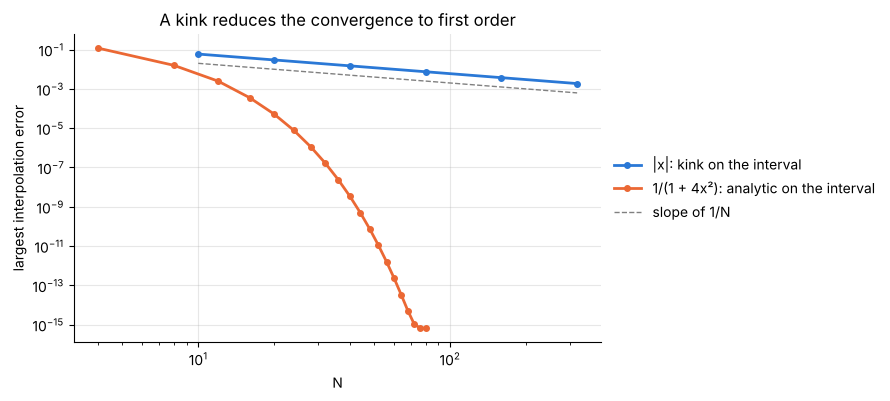

In [8]:
N_kink = np.array([10, 20, 40, 80, 160, 320])
kink_errors = np.array([np.abs(barycentric_interpolate(np.abs(chebyshev_points(N)), x_fine) - np.abs(x_fine)).max() for N in N_kink])
order = -np.polyfit(np.log(N_kink), np.log(kink_errors), 1)[0]

print("  N    largest error    error × N")
for N, e in zip(N_kink, kink_errors):
    print(f"{N:4d} {e:14.5f} {e * N:12.4f}")
print(f"algebraic order of convergence: {order:.3f}")

smooth = lambda x: 1 / (1 + 4 * x**2)                           # the analytic example of 4.7, ρ = 1.618
N_smooth = np.arange(4, 81, 4)
smooth_errors = [np.abs(barycentric_interpolate(smooth(chebyshev_points(N)), x_fine) - smooth(x_fine)).max() for N in N_smooth]

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.loglog(N_kink, kink_errors, "o-", ms=4, label="|x|: kink on the interval")
ax.loglog(N_smooth, smooth_errors, "o-", ms=4, label="1/(1 + 4x²): analytic on the interval")
ax.loglog(N_kink, 0.2 / N_kink, "--", color="0.5", lw=1, label="slope of 1/N")
ax.set(xlabel="N", ylabel="largest interpolation error", title="A kink reduces the convergence to first order")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [9]:
# verify: first-order convergence, the known behaviour of polynomial approximations of |x|
assert abs(order - 1) < 0.02
assert np.all(np.abs(kink_errors[:-1] / kink_errors[1:] - 2) < 0.02)        # doubling N halves the error

**Answer.** The largest error is 0.0592, 0.0298, 0.0149, 0.0075, 0.0037, 0.0019: it halves
each time $N$ doubles, the measured order is 0.998, and the error is close to $0.597/N$. The
convergence is algebraic of **first order**, where the analytic function $1/(1 + 4x^2)$ of 4.7
gained a digit for every 5 points and reached rounding level near $N = 75$. The reason is the
Bernstein ellipse. The rate $\rho^{-N}$ needs an ellipse with $\rho > 1$ inside which the
function is analytic. The kink of $|x|$ is at $x = 0$, on the interval itself, so every such
ellipse contains it, the only admissible value is $\rho = 1$, and the geometric factor is lost.
A thousand points give three digits. For data with a kink, split the interval at the kink and
interpolate each smooth piece separately.

## Exercise 4

The velocity across a thin shear layer is modelled by $u(x) = \tanh(10x)$ on $[-1, 1]$. It is
to be reconstructed from 21 probes ($N = 20$). Compare the largest reconstruction error for
probes at equally spaced and at Chebyshev positions. The nearest singularities of $u$ are at
$x = \pm i\pi/20$: compute $\rho$, predict how many Chebyshev probes are needed for an error
below $10^{-6}$, and check the prediction.

The poles at $\pm i\pi/20 = \pm0.157i$ are well inside the lens of 4.4, so equally spaced
probes should show the Runge phenomenon. For Chebyshev probes the poles lie at the ends of the
minor axis of the Bernstein ellipse, so $\rho = b + \sqrt{1 + b^2}$ with $b = \pi/20$. Taking
the constant in $\text{const}\times\rho^{-N}$ as 1, the error reaches $10^{-6}$ when
$N = \log 10^{6}/\log\rho$.

21 probes: largest error 32.66 equally spaced, 0.091 Chebyshev
ρ = 1.1693,  predicted N for an error of 1e-6: 88.3
measured ρ = 1.1685
error below 1e-6 first at N = 91 (92 probes), and for every N from 95 (96 probes)
constant in front of ρ^(-N) at N = 91: 1.2
constant in front of ρ^(-N) for N from 20 to 130: between 1.2 and 2.5


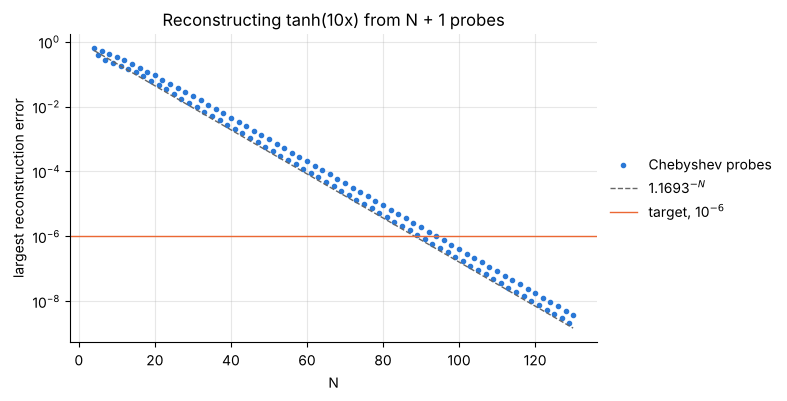

In [10]:
shear_layer = lambda x: np.tanh(10 * x)

def probe_error(points):
    return np.abs(lagrange_interpolate(points, shear_layer(points), x_fine) - shear_layer(x_fine)).max()

error_equispaced, error_chebyshev = probe_error(equispaced_points(20)), probe_error(chebyshev_points(20))
print(f"21 probes: largest error {error_equispaced:.2f} equally spaced, {error_chebyshev:.3f} Chebyshev")

b = np.pi / 20
rho = b + np.sqrt(1 + b**2)
N_predicted = np.log(1e6) / np.log(rho)
print(f"ρ = {rho:.4f},  predicted N for an error of 1e-6: {N_predicted:.1f}")

N_range = np.arange(4, 131)
chebyshev_errors = np.array([np.abs(barycentric_interpolate(shear_layer(chebyshev_points(N)), x_fine) - shear_layer(x_fine)).max()
                             for N in N_range])
N_first = N_range[chebyshev_errors < 1e-6][0]                   # the first N that reaches the target
N_safe = N_range[chebyshev_errors >= 1e-6][-1] + 1             # from here on every N reaches it
window = (N_range >= 20) & (N_range <= 120)
rho_measured = np.exp(-np.polyfit(N_range[window], np.log(chebyshev_errors[window]), 1)[0])
print(f"measured ρ = {rho_measured:.4f}")
print(f"error below 1e-6 first at N = {N_first} ({N_first + 1} probes), and for every N from {N_safe} ({N_safe + 1} probes)")
print(f"constant in front of ρ^(-N) at N = {N_first}: {chebyshev_errors[N_range == N_first][0] * rho**N_first:.1f}")
constants = (chebyshev_errors * rho**N_range)[N_range >= 20]
print(f"constant in front of ρ^(-N) for N from 20 to 130: between {constants.min():.1f} and {constants.max():.1f}")

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.semilogy(N_range, chebyshev_errors, "o", ms=3, label="Chebyshev probes")
ax.semilogy(N_range, rho ** (-N_range.astype(float)), "--", color="0.4", lw=1, label=f"{rho:.4f}$^{{-N}}$")
ax.axhline(1e-6, color="C1", lw=1, label="target, 10$^{-6}$")
ax.set(xlabel="N", ylabel="largest reconstruction error", title="Reconstructing tanh(10x) from N + 1 probes")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [11]:
# verify: the pole lies on the ellipse (distances to the foci ±1 add up to ρ + 1/ρ), the measured rate
# against the ellipse prediction, and the predicted probe count against the count found
assert abs(abs(1j * b - 1) + abs(1j * b + 1) - (rho + 1 / rho)) < 1e-12
assert abs(rho_measured / rho - 1) < 0.01
assert abs(N_first / N_predicted - 1) < 0.1 and abs(N_safe / N_predicted - 1) < 0.1
assert error_equispaced > 10 * error_chebyshev

**Answer.** With 21 probes the largest error is 32.66 for equally spaced positions (the
reconstruction is useless near the ends, a Runge phenomenon) and 0.091 for Chebyshev positions.
Neither is accurate yet: the layer is too thin for 21 probes. The ellipse through the poles has
$\rho = \pi/20 + \sqrt{1 + \pi^2/400} = 1.1693$, so about 15 probes are needed per digit, and
the prediction for an error of $10^{-6}$ is $N = 88.3$, about 89 probes. The computation gives a
measured $\rho = 1.1685$; the error first drops below $10^{-6}$ at $N = 91$ (92 probes) and
stays below it from $N = 95$ (96 probes), because odd $N$ does a little better than even $N$
here. The prediction is within 8 per cent, the shortfall being the constant in front of
$\rho^{-N}$, which is between 1.2 and 2.5 and was taken as 1. The number of sensors a profile needs
can be estimated from the position of its nearest complex singularity before any are installed.

## Exercise 5

Lebesgue constants in action. Sample $f(x) = \cos 3x$ at $N + 1 = 31$ points, add noise of
standard deviation $10^{-8}$ to the samples with `np.random.default_rng(0)`, and compute the
largest error of the interpolant on $[-1, 1]$, for equally spaced and for Chebyshev points.
Compare each error with $10^{-8}\,\Lambda_N$ from `lebesgue_constant`. Which point set
returns the noise unamplified?

The interpolant of noisy data is the interpolant of the clean data plus the interpolant of the
noise. With $N = 30$ the first part is accurate to rounding level for this smooth function, so
the error that remains is the interpolated noise, which can be as large as the largest noise
value times $\Lambda_N$. The same noise values are given to both point sets, so that only the
positions differ.

In [12]:
N = 30
signal = lambda x: np.cos(3 * x)
rng = np.random.default_rng(0)
noise = 1e-8 * rng.standard_normal(N + 1)

print("point set          error, clean data    error, noisy data    Λ_N        1e-8 Λ_N    error / 1e-8")
results = {}
for name, points in (("equally spaced", equispaced_points(N)), ("Chebyshev", chebyshev_points(N))):
    clean = np.abs(lagrange_interpolate(points, signal(points), x_fine) - signal(x_fine)).max()
    noisy = np.abs(lagrange_interpolate(points, signal(points) + noise, x_fine) - signal(x_fine)).max()
    Lambda = lebesgue_constant(points)
    results[name] = (clean, noisy, Lambda)
    print(f"{name:16s} {clean:14.1e} {noisy:20.1e} {Lambda:14.3g} {1e-8 * Lambda:12.1e} {noisy / 1e-8:12.3g}")
print(f"largest noise value: {np.abs(noise).max():.2e}")

point set          error, clean data    error, noisy data    Λ_N        1e-8 Λ_N    error / 1e-8
equally spaced          2.9e-09              2.3e-02        6.6e+06      6.6e-02     2.31e+06
Chebyshev               6.7e-16              2.3e-08           3.13      3.1e-08         2.34
largest noise value: 2.33e-08


In [13]:
# verify: each error respects the Lebesgue bound (largest noise value) × Λ_N plus the clean error,
# Λ_N for Chebyshev points is below the bound (2/π) log(N + 1) + 1 of 4.6, and the two errors differ by orders of magnitude
for clean, noisy, Lambda in results.values():
    assert noisy <= np.abs(noise).max() * Lambda + clean
assert results["Chebyshev"][2] < 2 / np.pi * np.log(N + 1) + 1
assert results["Chebyshev"][1] < 4 * np.abs(noise).max()
assert results["equally spaced"][1] > 1e3 * results["Chebyshev"][1]

**Answer.** With equally spaced points the largest error is $2.3\times10^{-2}$, which is
$2.3\times10^{6}$ times the noise level; the Lebesgue constant is $\Lambda_{30} = 6.6\times10^{6}$,
so $10^{-8}\Lambda_{30} = 6.6\times10^{-2}$: the noise is amplified a million-fold, within a factor
of seven of the worst case that the Lebesgue constant allows. With Chebyshev points the largest error is $2.3\times10^{-8}$, the size of the
largest noise value itself, and $\Lambda_{30} = 3.13$. The Chebyshev points return the noise
unamplified. The equally spaced points turn eight-digit data into a two-digit result, and even
with no added noise their error is $2.9\times10^{-9}$, from rounding errors alone.